Number of old images: 19
Number of new images: 20

Building the similarity matrix...
Extracting features from old images...
  [OLD] Features extracted: im(1).jpg (1/19)
  [OLD] Features extracted: im(10).jpg (2/19)
  [OLD] Features extracted: im(11).jpg (3/19)
  [OLD] Features extracted: im(12).jpg (4/19)
  [OLD] Features extracted: im(13).jpg (5/19)
  [OLD] Features extracted: im(14).jpg (6/19)
  [OLD] Features extracted: im(18).jpg (7/19)
  [OLD] Features extracted: im(19).jpg (8/19)
  [OLD] Features extracted: im(2).jpg (9/19)
  [OLD] Features extracted: im(20).jpg (10/19)
  [OLD] Features extracted: im(21).jpg (11/19)
  [OLD] Features extracted: im(22).jpg (12/19)
  [OLD] Features extracted: im(3).jpg (13/19)
  [OLD] Features extracted: im(4).jpg (14/19)
  [OLD] Features extracted: im(5).jpg (15/19)
  [OLD] Features extracted: im(6).jpg (16/19)
  [OLD] Features extracted: im(7).jpg (17/19)
  [OLD] Features extracted: im(8).jpg (18/19)
  [OLD] Features extracted: im(9).jpg (19/19)
E

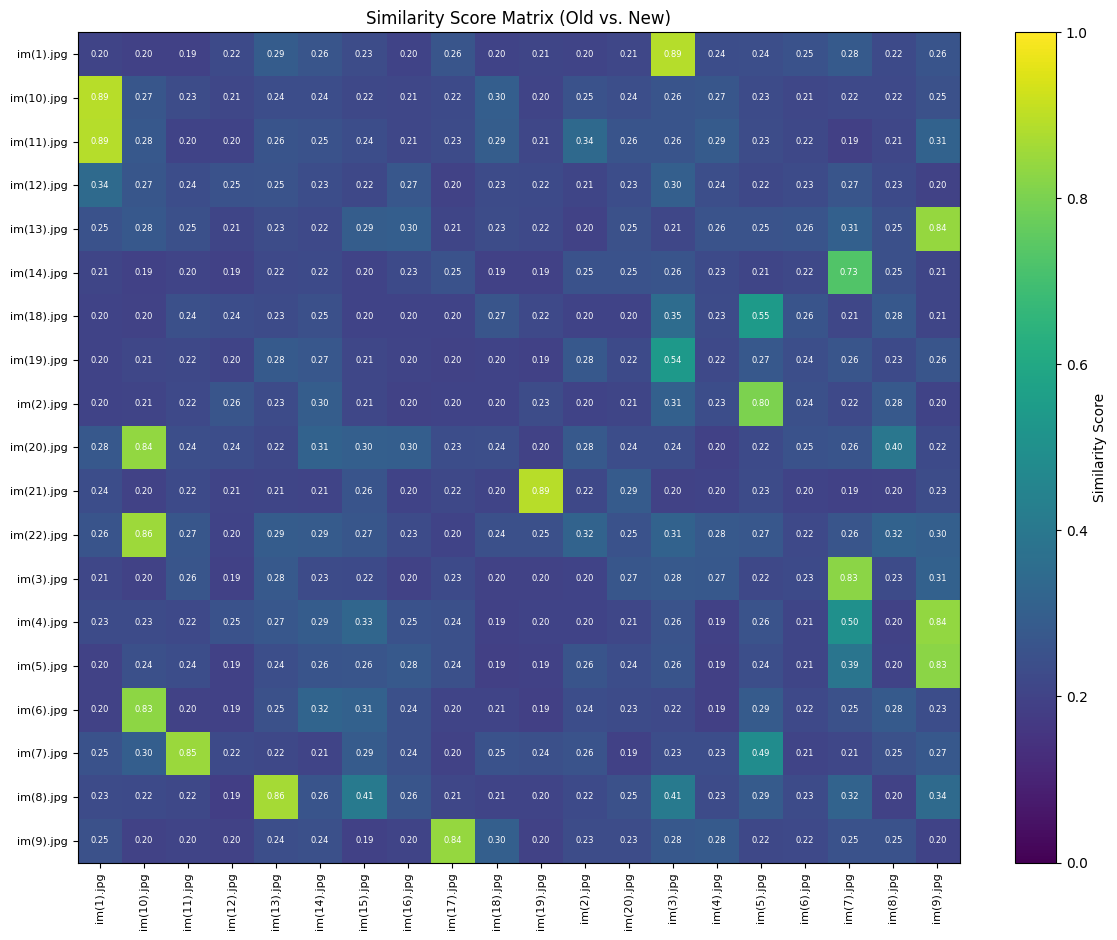

Similarity heatmap saved to: /content/drive/MyDrive/match_visualizations/score_heatmap.png

Performing final matching...
Matching mode: CLASSIFICATION - Independent best-match selection for each old image.
Results saved to: /content/drive/MyDrive/matched_images.txt

Matching Results:
  im(10).jpg                     -> im(1).jpg                      | score=0.893 | status=matched
  im(21).jpg                     -> im(19).jpg                     | score=0.893 | status=matched
  im(1).jpg                      -> im(3).jpg                      | score=0.890 | status=matched
  im(11).jpg                     -> im(1).jpg                      | score=0.890 | status=matched
  im(8).jpg                      -> im(13).jpg                     | score=0.863 | status=matched
  im(22).jpg                     -> im(10).jpg                     | score=0.855 | status=matched
  im(7).jpg                      -> im(11).jpg                     | score=0.851 | status=matched
  im(9).jpg                  

In [ ]:

import cv2
import os
import threading
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont
from scipy.optimize import linear_sum_assignment
from concurrent.futures import ThreadPoolExecutor


# ==================== CONFIGURATION ====================

OLD_IMAGES_FOLDER = '/content/drive/MyDrive/Banknote test'
NEW_IMAGES_FOLDER = '/content/drive/MyDrive/Banknote Dataset'

OUTPUT_TXT_PATH = '/content/drive/MyDrive/matched_images.txt'
OUTPUT_VIS_FOLDER = '/content/drive/MyDrive/match_visualizations'
OUTPUT_GIF_PATH = os.path.join(
    OUTPUT_VIS_FOLDER,
    'banknote_matching.gif'
)

STANDARD_WIDTH = 800

WEIGHT_STRUCTURE = 0.65
WEIGHT_COLOR = 0.35

MATCHING_MODE = "classification"

MIN_ACCEPT_SCORE = 0.35
MIN_MATCH_COUNT_FOR_HOMOGRAPHY = 8
LOW_KEYPOINT_THRESHOLD = 60

USE_SIFT_FALLBACK = True

MAX_WORKERS = min(8, (os.cpu_count() or 4) * 2)

DUMMY_COST = 1.0 - MIN_ACCEPT_SCORE

GIF_DURATION = 1800
GIF_MAX_WIDTH = 1200
GIF_MAX_HEIGHT = 600


# ==================== IMAGE PREPROCESSING ====================

def load_and_normalize(image_path, target_width=STANDARD_WIDTH):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Failed to load image: {image_path}")

    h, w = image.shape[:2]

    if w == 0:
        raise ValueError(f"Invalid image dimensions: {image_path}")

    scale = target_width / w
    target_height = max(1, int(h * scale))

    return cv2.resize(
        image,
        (target_width, target_height),
        interpolation=cv2.INTER_AREA
    )


def enhance_for_features(image_bgr):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(
        clipLimit=2.5,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    return cv2.bilateralFilter(
        enhanced,
        d=5,
        sigmaColor=50,
        sigmaSpace=50
    )


def unsharp_mask(gray_image, amount=1.2, radius=3):
    blurred = cv2.GaussianBlur(
        gray_image,
        (0, 0),
        radius
    )

    return cv2.addWeighted(
        gray_image,
        1 + amount,
        blurred,
        -amount,
        0
    )


def enhance_for_features_strong(image_bgr):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(
        clipLimit=4.5,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    enhanced = unsharp_mask(
        enhanced,
        amount=1.2,
        radius=3
    )

    return cv2.bilateralFilter(
        enhanced,
        d=5,
        sigmaColor=50,
        sigmaSpace=50
    )


# ==================== FEATURE EXTRACTION ====================

_thread_local = threading.local()


def _get_orb():
    if not hasattr(_thread_local, "orb"):
        _thread_local.orb = cv2.ORB_create(
            nfeatures=3000,
            scaleFactor=1.2,
            nlevels=8
        )

    return _thread_local.orb


def _get_sift():
    if not hasattr(_thread_local, "sift"):
        _thread_local.sift = cv2.SIFT_create(
            nfeatures=3000,
            contrastThreshold=0.02,
            edgeThreshold=15
        )

    return _thread_local.sift


def extract_orb_features(gray_image):
    return _get_orb().detectAndCompute(gray_image, None)


def extract_sift_features(gray_image):
    return _get_sift().detectAndCompute(gray_image, None)


# ==================== STRUCTURAL SIMILARITY ====================

def _structural_similarity_generic(
    kp1,
    des1,
    kp2,
    des2,
    norm_type,
    score_cap,
    ratio=0.75,
    return_matches=False
):
    if (
        des1 is None
        or des2 is None
        or len(des1) < 2
        or len(des2) < 2
    ):
        return (0.0, None, []) if return_matches else 0.0

    bf_matcher = cv2.BFMatcher(norm_type)

    raw_matches = bf_matcher.knnMatch(
        des1,
        des2,
        k=2
    )

    good_matches = []

    for pair in raw_matches:
        if len(pair) == 2:
            m, n = pair

            if m.distance < ratio * n.distance:
                good_matches.append(m)

    if len(good_matches) < MIN_MATCH_COUNT_FOR_HOMOGRAPHY:
        score = min(len(good_matches) / 50.0, 1.0)

        return (
            (score, None, good_matches)
            if return_matches
            else score
        )

    src_pts = np.float32([
        kp1[match.queryIdx].pt
        for match in good_matches
    ]).reshape(-1, 1, 2)

    dst_pts = np.float32([
        kp2[match.trainIdx].pt
        for match in good_matches
    ]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        src_pts,
        dst_pts,
        cv2.RANSAC,
        5.0
    )

    if mask is None:
        score = min(len(good_matches) / 50.0, 1.0)

        return (
            (score, H, good_matches)
            if return_matches
            else score
        )

    inliers = int(mask.sum())
    score = min(inliers / score_cap, 1.0)

    inlier_matches = [
        match
        for match, is_inlier in zip(
            good_matches,
            mask.ravel()
        )
        if is_inlier
    ]

    return (
        (score, H, inlier_matches)
        if return_matches
        else score
    )


def structural_similarity_orb(
    gray1,
    gray2,
    kp1,
    des1,
    kp2,
    des2,
    return_matches=False
):
    return _structural_similarity_generic(
        kp1,
        des1,
        kp2,
        des2,
        cv2.NORM_HAMMING,
        150.0,
        return_matches=return_matches
    )


def structural_similarity_sift(
    kp1,
    des1,
    kp2,
    des2,
    return_matches=False
):
    return _structural_similarity_generic(
        kp1,
        des1,
        kp2,
        des2,
        cv2.NORM_L2,
        120.0,
        return_matches=return_matches
    )


def combined_structural_similarity(
    features1,
    features2,
    return_details=False
):
    kp1_orb, des1_orb, kp1_sift, des1_sift = features1
    kp2_orb, des2_orb, kp2_sift, des2_sift = features2

    orb_score = structural_similarity_orb(
        None,
        None,
        kp1_orb,
        des1_orb,
        kp2_orb,
        des2_orb
    )

    sift_score = (
        structural_similarity_sift(
            kp1_sift,
            des1_sift,
            kp2_sift,
            des2_sift
        )
        if USE_SIFT_FALLBACK
        else 0.0
    )

    final_score = max(orb_score, sift_score)

    if return_details:
        winner = "SIFT" if sift_score > orb_score else "ORB"

        return final_score, {
            "orb_score": orb_score,
            "sift_score": sift_score,
            "winner": winner
        }

    return final_score


# ==================== COLOR SIMILARITY ====================

def color_similarity_hsv(image1_bgr, image2_bgr):
    hsv1 = cv2.cvtColor(
        image1_bgr,
        cv2.COLOR_BGR2HSV
    )

    hsv2 = cv2.cvtColor(
        image2_bgr,
        cv2.COLOR_BGR2HSV
    )

    hist1 = cv2.calcHist(
        [hsv1],
        [0, 1],
        None,
        [50, 60],
        [0, 180, 0, 256]
    )

    hist2 = cv2.calcHist(
        [hsv2],
        [0, 1],
        None,
        [50, 60],
        [0, 180, 0, 256]
    )

    cv2.normalize(
        hist1,
        hist1,
        0,
        1,
        cv2.NORM_MINMAX
    )

    cv2.normalize(
        hist2,
        hist2,
        0,
        1,
        cv2.NORM_MINMAX
    )

    correlation = cv2.compareHist(
        hist1,
        hist2,
        cv2.HISTCMP_CORREL
    )

    return max(0.0, (correlation + 1) / 2)


# ==================== FEATURE CACHE ====================

def _load_and_featurize(path, verbose=True):
    img = load_and_normalize(path)

    gray = enhance_for_features(img)

    kp_orb, des_orb = extract_orb_features(gray)

    used_strong = False

    if des_orb is None or len(kp_orb) < LOW_KEYPOINT_THRESHOLD:
        gray_strong = enhance_for_features_strong(img)

        kp_orb_strong, des_orb_strong = extract_orb_features(
            gray_strong
        )

        if (
            des_orb_strong is not None
            and (
                des_orb is None
                or len(kp_orb_strong) > len(kp_orb)
            )
        ):
            gray = gray_strong
            kp_orb = kp_orb_strong
            des_orb = des_orb_strong

            used_strong = True

    kp_sift, des_sift = extract_sift_features(gray)

    if verbose and used_strong:
        n_kp = len(kp_orb) if kp_orb else 0

        print(
            f"    Warning: Low feature count for "
            f"{os.path.basename(path)}. "
            f"Stronger preprocessing applied ({n_kp} keypoints)."
        )

    return path, (
        img,
        gray,
        kp_orb,
        des_orb,
        kp_sift,
        des_sift
    )


def _build_cache_parallel(paths, label, verbose=True):
    cache = {}

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = [
            executor.submit(
                _load_and_featurize,
                path,
                verbose
            )
            for path in paths
        ]

        for idx, future in enumerate(futures, start=1):
            path, data = future.result()

            cache[path] = data

            if verbose:
                print(
                    f"  [{label}] Features extracted: "
                    f"{os.path.basename(path)} "
                    f"({idx}/{len(paths)})"
                )

    return cache


# ==================== SCORE MATRIX ====================

def build_score_matrix(old_paths, new_paths, verbose=True):
    n_old = len(old_paths)
    n_new = len(new_paths)

    score_matrix = np.zeros(
        (n_old, n_new),
        dtype=np.float32
    )

    if verbose:
        print("Extracting features from old images...")

    old_cache = _build_cache_parallel(
        old_paths,
        "OLD",
        verbose
    )

    if verbose:
        print("Extracting features from new images...")

    new_cache = _build_cache_parallel(
        new_paths,
        "NEW",
        verbose
    )

    def _score_row(i, old_path):
        (
            old_img,
            old_gray,
            old_kp_orb,
            old_des_orb,
            old_kp_sift,
            old_des_sift
        ) = old_cache[old_path]

        old_features = (
            old_kp_orb,
            old_des_orb,
            old_kp_sift,
            old_des_sift
        )

        row_scores = np.zeros(
            n_new,
            dtype=np.float32
        )

        for j, new_path in enumerate(new_paths):
            (
                new_img,
                new_gray,
                new_kp_orb,
                new_des_orb,
                new_kp_sift,
                new_des_sift
            ) = new_cache[new_path]

            new_features = (
                new_kp_orb,
                new_des_orb,
                new_kp_sift,
                new_des_sift
            )

            struct_score = combined_structural_similarity(
                old_features,
                new_features
            )

            color_score = color_similarity_hsv(
                old_img,
                new_img
            )

            row_scores[j] = (
                WEIGHT_STRUCTURE * struct_score
                + WEIGHT_COLOR * color_score
            )

        return i, row_scores

    if verbose:
        print("Calculating the similarity score matrix...")

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = [
            executor.submit(
                _score_row,
                i,
                old_path
            )
            for i, old_path in enumerate(old_paths)
        ]

        for idx, future in enumerate(futures, start=1):
            i, row_scores = future.result()

            score_matrix[i] = row_scores

            if verbose:
                print(
                    f"  Score row calculated: "
                    f"{os.path.basename(old_paths[i])} "
                    f"({idx}/{n_old})"
                )

    return score_matrix, old_cache, new_cache


# ==================== MATCH CLASSIFICATION ====================

def classify_matches(
    score_matrix,
    old_paths,
    new_paths,
    min_score=MIN_ACCEPT_SCORE
):
    results = []

    for i, old_path in enumerate(old_paths):
        row = score_matrix[i]

        best_j = int(np.argmax(row))
        best_score = float(row[best_j])

        if best_score >= min_score:
            results.append({
                "old_image": old_path,
                "new_image": new_paths[best_j],
                "score": best_score,
                "status": "matched"
            })
        else:
            results.append({
                "old_image": old_path,
                "new_image": None,
                "score": best_score,
                "status": "no_confident_match"
            })

    results.sort(
        key=lambda result: result["score"],
        reverse=True
    )

    return results


def optimal_assignment(
    score_matrix,
    old_paths,
    new_paths,
    min_score=MIN_ACCEPT_SCORE
):
    n_old, n_new = score_matrix.shape
    size = n_old + n_new

    cost_matrix = np.full(
        (size, size),
        DUMMY_COST,
        dtype=np.float32
    )

    cost_matrix[:n_old, :n_new] = 1.0 - score_matrix

    row_idx, col_idx = linear_sum_assignment(cost_matrix)

    results = []

    for r, c in zip(row_idx, col_idx):
        if r >= n_old:
            continue

        if c >= n_new:
            results.append({
                "old_image": old_paths[r],
                "new_image": None,
                "score": 0.0,
                "status": "no_confident_match"
            })

            continue

        score = float(score_matrix[r, c])

        status = (
            "matched"
            if score >= min_score
            else "low_confidence"
        )

        results.append({
            "old_image": old_paths[r],
            "new_image": new_paths[c],
            "score": score,
            "status": status
        })

    results.sort(
        key=lambda result: result["score"],
        reverse=True
    )

    return results


# ==================== TOP-K REPORT ====================

def top_k_candidates(
    score_matrix,
    old_paths,
    new_paths,
    k=3
):
    report = {}

    for i, old_path in enumerate(old_paths):
        row = score_matrix[i]

        top_idx = np.argsort(row)[::-1][:k]

        report[old_path] = [
            (new_paths[j], float(row[j]))
            for j in top_idx
        ]

    return report


def print_top_k_report(report):
    for old_path, candidates in report.items():
        print(f"\n{os.path.basename(old_path)}:")

        for rank, (new_path, score) in enumerate(
            candidates,
            start=1
        ):
            marker = "  <-- Best candidate" if rank == 1 else ""

            print(
                f"   {rank}. "
                f"{os.path.basename(new_path):30s} "
                f"score={score:.3f}{marker}"
            )


# ==================== SAVE TEXT RESULTS ====================

def save_results_txt(results, path=None):
    if path is None:
        path = OUTPUT_TXT_PATH

    with open(path, "w", encoding="utf-8") as file:
        for result in results:
            new_name = (
                os.path.basename(result["new_image"])
                if result["new_image"]
                else "---"
            )

            file.write(
                f"{os.path.basename(result['old_image'])}"
                f" -> {new_name}"
                f" | score={result['score']:.3f}"
                f" | status={result['status']}\n"
            )

    print(f"Results saved to: {path}")


# ==================== GIF GENERATION ====================

def create_matching_gif(
    results,
    output_path=None,
    duration=GIF_DURATION
):
    if output_path is None:
        output_path = OUTPUT_GIF_PATH

    os.makedirs(
        os.path.dirname(output_path) or ".",
        exist_ok=True
    )

    canvas_width = GIF_MAX_WIDTH
    canvas_height = GIF_MAX_HEIGHT

    header_height = 75
    footer_height = 65
    gap = 30

    panel_width = (canvas_width - 3 * gap) // 2
    panel_height = canvas_height - header_height - footer_height - 2 * gap

    frames = []

    try:
        title_font = ImageFont.truetype(
            "DejaVuSans.ttf",
            23
        )

        font = ImageFont.truetype(
            "DejaVuSans.ttf",
            16
        )

        small_font = ImageFont.truetype(
            "DejaVuSans.ttf",
            12
        )

    except OSError:
        title_font = ImageFont.load_default()
        font = ImageFont.load_default()
        small_font = ImageFont.load_default()

    def load_rgb(path):
        image = cv2.imread(path)

        if image is None:
            return None

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        return Image.fromarray(image)

    def fit_image(image, max_width, max_height):
        image = image.copy()

        image.thumbnail(
            (max_width, max_height),
            Image.Resampling.LANCZOS
        )

        return image

    def shorten(text, max_length=42):
        if len(text) <= max_length:
            return text

        return text[:max_length - 3] + "..."

    valid_results = [
        result
        for result in results
        if result.get("old_image")
    ]

    if not valid_results:
        raise ValueError(
            "No valid matching results available for GIF generation."
        )

    total_results = len(valid_results)

    for index, result in enumerate(valid_results, start=1):
        old_image = load_rgb(result["old_image"])

        if old_image is None:
            print(
                f"Skipping unreadable old image: "
                f"{result['old_image']}"
            )
            continue

        new_image = None

        if result.get("new_image") is not None:
            new_image = load_rgb(result["new_image"])

        frame = Image.new(
            "RGB",
            (canvas_width, canvas_height),
            (248, 249, 252)
        )

        draw = ImageDraw.Draw(frame)

        draw.text(
            (gap, 18),
            "BANKNOTE MATCHING",
            fill=(25, 35, 55),
            font=title_font
        )

        draw.text(
            (canvas_width - 230, 25),
            f"Result {index} / {total_results}",
            fill=(75, 85, 105),
            font=font
        )

        old_panel_x = gap
        new_panel_x = 2 * gap + panel_width
        panel_y = header_height

        old_name = shorten(
            os.path.basename(result["old_image"])
        )

        new_name = (
            shorten(os.path.basename(result["new_image"]))
            if result.get("new_image")
            else "No confident match"
        )

        draw.text(
            (old_panel_x, panel_y),
            f"OLD: {old_name}",
            fill=(35, 45, 65),
            font=font
        )

        draw.text(
            (new_panel_x, panel_y),
            f"NEW: {new_name}",
            fill=(35, 45, 65),
            font=font
        )

        image_y = panel_y + 30
        image_area_height = panel_height - 35

        old_image = fit_image(
            old_image,
            panel_width - 12,
            image_area_height
        )

        old_x = (
            old_panel_x
            + (panel_width - old_image.width) // 2
        )

        old_y = (
            image_y
            + (image_area_height - old_image.height) // 2
        )

        frame.paste(
            old_image,
            (old_x, old_y)
        )

        if new_image is not None:
            new_image = fit_image(
                new_image,
                panel_width - 12,
                image_area_height
            )

            new_x = (
                new_panel_x
                + (panel_width - new_image.width) // 2
            )

            new_y = (
                image_y
                + (image_area_height - new_image.height) // 2
            )

            frame.paste(
                new_image,
                (new_x, new_y)
            )

        else:
            message = "NO CONFIDENT MATCH"

            bbox = draw.textbbox(
                (0, 0),
                message,
                font=font
            )

            text_width = bbox[2] - bbox[0]
            text_height = bbox[3] - bbox[1]

            draw.text(
                (
                    new_panel_x
                    + (panel_width - text_width) // 2,
                    image_y
                    + (image_area_height - text_height) // 2
                ),
                message,
                fill=(190, 45, 45),
                font=font
            )

        draw.rectangle(
            (
                old_panel_x - 5,
                panel_y - 5,
                old_panel_x + panel_width,
                image_y + image_area_height + 5
            ),
            outline=(205, 210, 220),
            width=2
        )

        draw.rectangle(
            (
                new_panel_x - 5,
                panel_y - 5,
                new_panel_x + panel_width,
                image_y + image_area_height + 5
            ),
            outline=(205, 210, 220),
            width=2
        )

        score = float(result["score"])
        status = result["status"].upper()

        draw.text(
            (gap, canvas_height - footer_height + 10),
            f"Similarity Score: {score:.3f}",
            fill=(25, 35, 55),
            font=font
        )

        status_color = (
            (35, 135, 75)
            if status == "MATCHED"
            else (190, 75, 45)
        )

        draw.text(
            (gap, canvas_height - 30),
            f"Status: {status}",
            fill=status_color,
            font=small_font
        )

        draw.text(
            (
                canvas_width - 350,
                canvas_height - 30
            ),
            "ORB + SIFT + HSV Color",
            fill=(85, 95, 110),
            font=small_font
        )

        # Convert frames to a consistent palette for GIF output.
        frames.append(
            frame.convert("P", palette=Image.Palette.ADAPTIVE, colors=128)
        )

        print(
            f"GIF frame prepared: {index}/{total_results}"
        )

    if not frames:
        raise ValueError(
            "No readable image pairs were available for the GIF."
        )

    frames[0].save(
        output_path,
        save_all=True,
        append_images=frames[1:],
        duration=duration,
        loop=0,
        optimize=True,
        disposal=2
    )

    print(f"Animated GIF saved to: {output_path}")
    print(f"Total frames: {len(frames)}")

    return output_path


# ==================== SCORE MATRIX VISUALIZATION ====================

def visualize_score_matrix(
    score_matrix,
    old_paths,
    new_paths,
    save_path=None,
    show=True
):
    if save_path is None:
        save_path = os.path.join(
            OUTPUT_VIS_FOLDER,
            "score_heatmap.png"
        )

    os.makedirs(
        os.path.dirname(save_path) or ".",
        exist_ok=True
    )

    fig, ax = plt.subplots(
        figsize=(
            max(6, len(new_paths) * 0.6),
            max(5, len(old_paths) * 0.5)
        )
    )

    im = ax.imshow(
        score_matrix,
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    ax.set_xticks(range(len(new_paths)))

    ax.set_xticklabels(
        [os.path.basename(path) for path in new_paths],
        rotation=90,
        fontsize=8
    )

    ax.set_yticks(range(len(old_paths)))

    ax.set_yticklabels(
        [os.path.basename(path) for path in old_paths],
        fontsize=8
    )

    if score_matrix.size <= 400:
        for i in range(score_matrix.shape[0]):
            for j in range(score_matrix.shape[1]):
                ax.text(
                    j,
                    i,
                    f"{score_matrix[i, j]:.2f}",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=6
                )

    ax.set_title("Similarity Score Matrix (Old vs. New)")

    fig.colorbar(
        im,
        ax=ax,
        label="Similarity Score"
    )

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=150
    )

    if show:
        plt.show()

    plt.close(fig)

    print(f"Similarity heatmap saved to: {save_path}")


# ==================== MAIN PIPELINE ====================

def run_pipeline():
    if not os.path.isdir(OLD_IMAGES_FOLDER):
        raise FileNotFoundError(
            f"Old images folder not found: {OLD_IMAGES_FOLDER}"
        )

    if not os.path.isdir(NEW_IMAGES_FOLDER):
        raise FileNotFoundError(
            f"New images folder not found: {NEW_IMAGES_FOLDER}"
        )

    old_images = sorted([
        os.path.join(OLD_IMAGES_FOLDER, filename)
        for filename in os.listdir(OLD_IMAGES_FOLDER)
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    new_images = sorted([
        os.path.join(NEW_IMAGES_FOLDER, filename)
        for filename in os.listdir(NEW_IMAGES_FOLDER)
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    print(f"Number of old images: {len(old_images)}")
    print(f"Number of new images: {len(new_images)}")

    if not old_images:
        raise ValueError(
            f"No supported images found in: {OLD_IMAGES_FOLDER}"
        )

    if not new_images:
        raise ValueError(
            f"No supported images found in: {NEW_IMAGES_FOLDER}"
        )

    print("\nBuilding the similarity matrix...")

    score_matrix, _, _ = build_score_matrix(
        old_images,
        new_images
    )

    visualize_score_matrix(
        score_matrix,
        old_images,
        new_images
    )

    print("\nPerforming final matching...")

    if MATCHING_MODE == "unique":
        print(
            "Matching mode: UNIQUE - "
            "One-to-one assignment using the Hungarian algorithm."
        )

        results = optimal_assignment(
            score_matrix,
            old_images,
            new_images
        )

    else:
        print(
            "Matching mode: CLASSIFICATION - "
            "Independent best-match selection for each old image."
        )

        results = classify_matches(
            score_matrix,
            old_images,
            new_images
        )

    save_results_txt(results)

    print("\nMatching Results:")

    for result in results:
        new_name = (
            os.path.basename(result["new_image"])
            if result["new_image"]
            else "(No confident match)"
        )

        print(
            f"  {os.path.basename(result['old_image']):30s}"
            f" -> {new_name:30s}"
            f" | score={result['score']:.3f}"
            f" | status={result['status']}"
        )

    print("\n" + "=" * 60)
    print("Top-K Candidate Report")
    print("=" * 60)

    report = top_k_candidates(
        score_matrix,
        old_images,
        new_images,
        k=3
    )

    print_top_k_report(report)

    print("\nGenerating the animated GIF...")

    create_matching_gif(
        results,
        output_path=OUTPUT_GIF_PATH,
        duration=GIF_DURATION
    )

    print("\nPipeline completed successfully.")

    return results


if __name__ == "__main__":
    run_pipeline()


In [ ]:
!pip install pytesseract

In [ ]:
!pip install opencv-contrib-python